# Montgom Project
Use the Python (MTGP) kernel after completing the setup in the project README.

In [1]:
import mtgp

print(mtgp.__file__)

/Users/thartigan/Documents/Classes/Med-Img/montgom_project/src/mtgp/__init__.py


In [1]:
from mtgp import Trial
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import binary_dilation
from skimage import measure

cmap = plt.colormaps["gray"].copy()
cmap.set_bad("red")

trial = Trial()
trial.data

Skipping MCUCXR_0354_1: image and lung mask dimensions do not match.


,patient_id,patient_num,label,classification,sex,age_years,age_raw,findings,clinical_reading,rows,...,image_mode,image_path,clinical_path,left_mask_path,right_mask_path,issues,masks_match_image,has_clinical,has_left_mask,has_right_mask
0,MCUCXR_0001_0,1,0,normal,F,27,027Y,normal,Patient's Sex: F \nPatient's Age: 027Y\nnormal\n,4020,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True
1,MCUCXR_0002_0,2,0,normal,F,40,040Y,normal,Patient's Sex: F \nPatient's Age: 040Y\nnormal\n,4020,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True
2,MCUCXR_0003_0,3,0,normal,F,21,021Y,normal,Patient's Sex: F \nPatient's Age: 021Y\nnormal\n,4892,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True
3,MCUCXR_0004_0,4,0,normal,F,11,011Y,normal,Patient's Sex: F \nPatient's Age: 011Y\nnormal\n,4892,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True
4,MCUCXR_0005_0,5,0,normal,M,33,033Y,normal,Patient's Sex: M \nPatient's Age: 033Y\nnormal\n,4892,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
132,MCUCXR_0383_1,383,1,abnormal,F,14,014Y,calcified granuloma LUL behind 4th rib anterior,Patient's Sex: F \nPatient's Age: 014Y\ncalcif...,4892,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True
133,MCUCXR_0387_1,387,1,abnormal,M,42,042Y,inactive scars RUL,Patient's Sex: M \nPatient's Age: 042Y\ninacti...,4892,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True
134,MCUCXR_0390_1,390,1,abnormal,M,52,052Y,Rt apical scarring. LUL scars and some infiltr...,Patient's Sex: M \nPatient's Age: 052Y\nRt api...,4892,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True
135,MCUCXR_0393_1,393,1,abnormal,F,30,030Y,left pleural effusion; best seen on lateral vi...,Patient's Sex: F \nPatient's Age: 030Y\nleft p...,4892,...,L,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,/Users/thartigan/Documents/Classes/Med-Img/mon...,[],True,True,True,True


In [3]:
patient = trial[0]
print(patient)
print(patient.clinical_reading)
print("Shape:", patient.matrix_size, "Spacing (mm):", patient.pixel_spacing_mm)
patient.metadata

Patient('MCUCXR_0001_0', normal, shape=(4020, 4892))
Patient's Sex: F 
Patient's Age: 027Y
normal

Shape: (4020, 4892) Spacing (mm): (0.0875, 0.0875)


{'image': {'format': 'PNG',
  'mode': 'L',
  'matrix_size': (4020, 4892),
  'info': {},
  'file_size_bytes': 5202442,
  'bit_depth': 8,
  'color_type': 0},
 'masks': {'left': {'format': 'PNG',
   'mode': '1',
   'matrix_size': (4020, 4892),
   'info': {},
   'file_size_bytes': 16254,
   'bit_depth': 1,
   'color_type': 0},
  'right': {'format': 'PNG',
   'mode': '1',
   'matrix_size': (4020, 4892),
   'info': {},
   'file_size_bytes': 16029,
   'bit_depth': 1,
   'color_type': 0}},
 'pixel_spacing_mm': (0.0875, 0.0875),
 'pixel_spacing_source': 'NLM-MontgomeryCXRSet-ReadMe.pdf: dataset-level image parameters',
 'documented_gray_level_bits': 12,
 'clinical_fields': {'sex': 'F', 'age': '027Y'},
 'issues': [],
 'documentation_path': PosixPath('/Users/thartigan/Documents/Classes/Med-Img/montgom_project/data/MontgomerySet/NLM-MontgomeryCXRSet-ReadMe.pdf'),
 'label_source': 'filename suffix: 0 normal, 1 abnormal'}

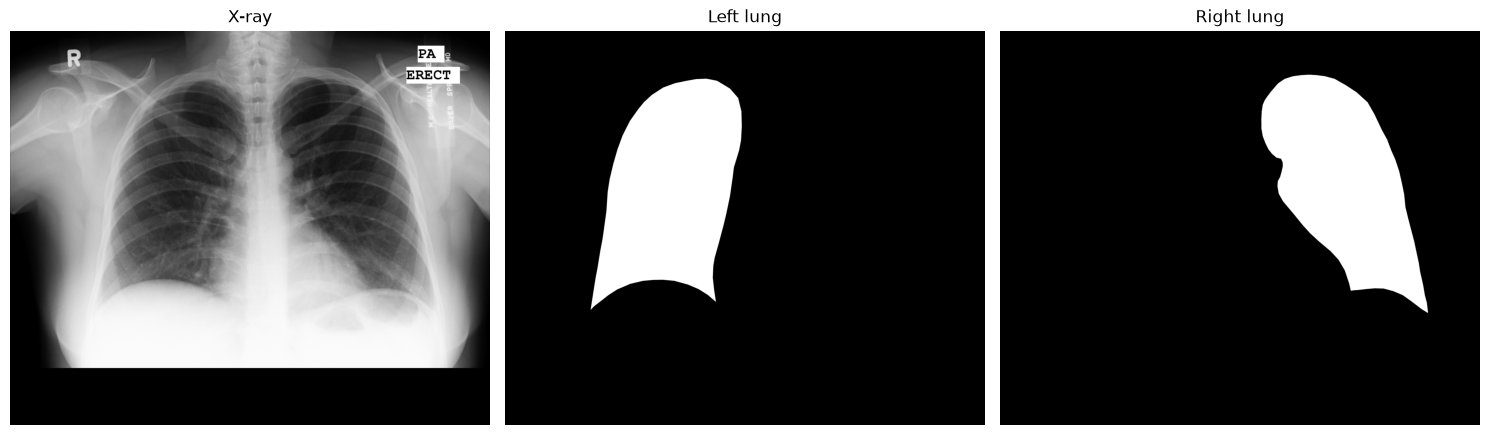

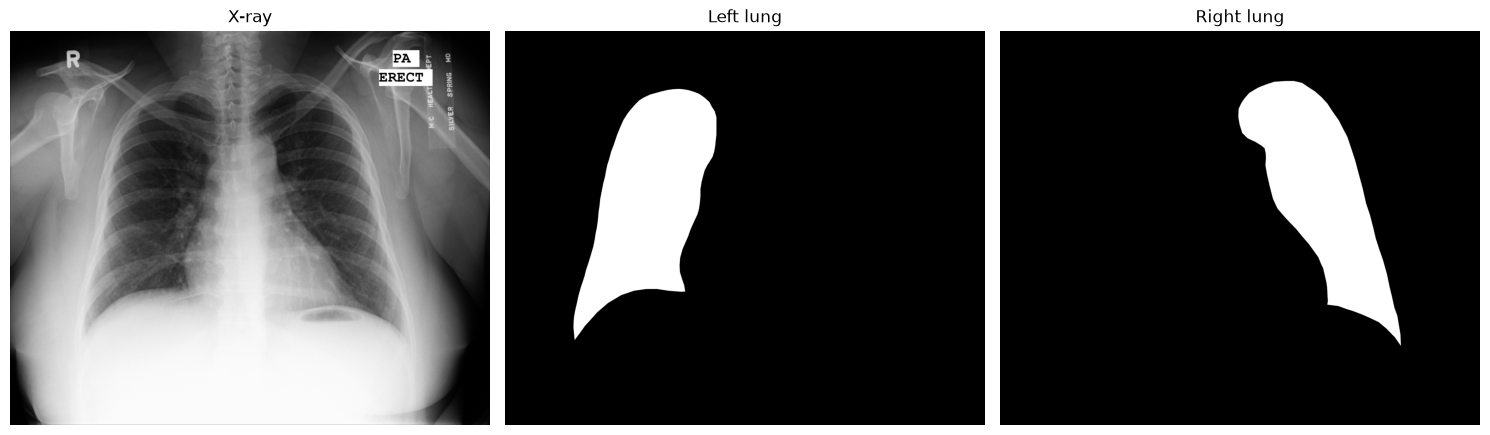

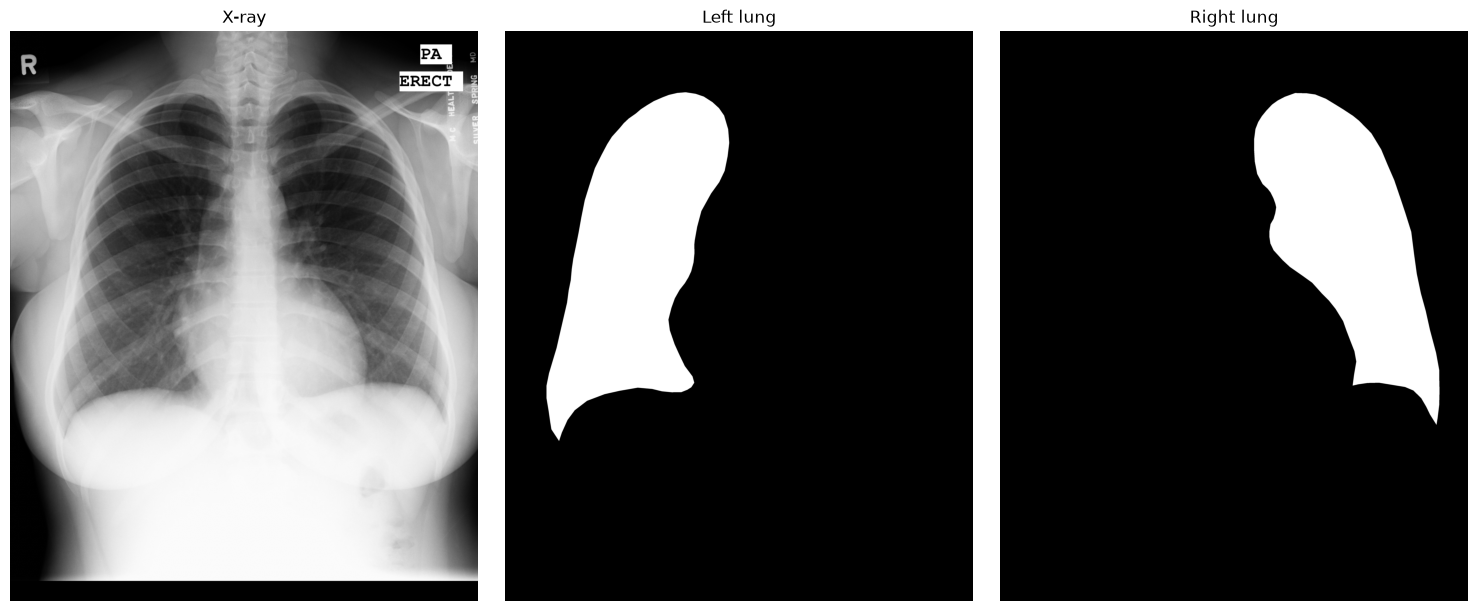

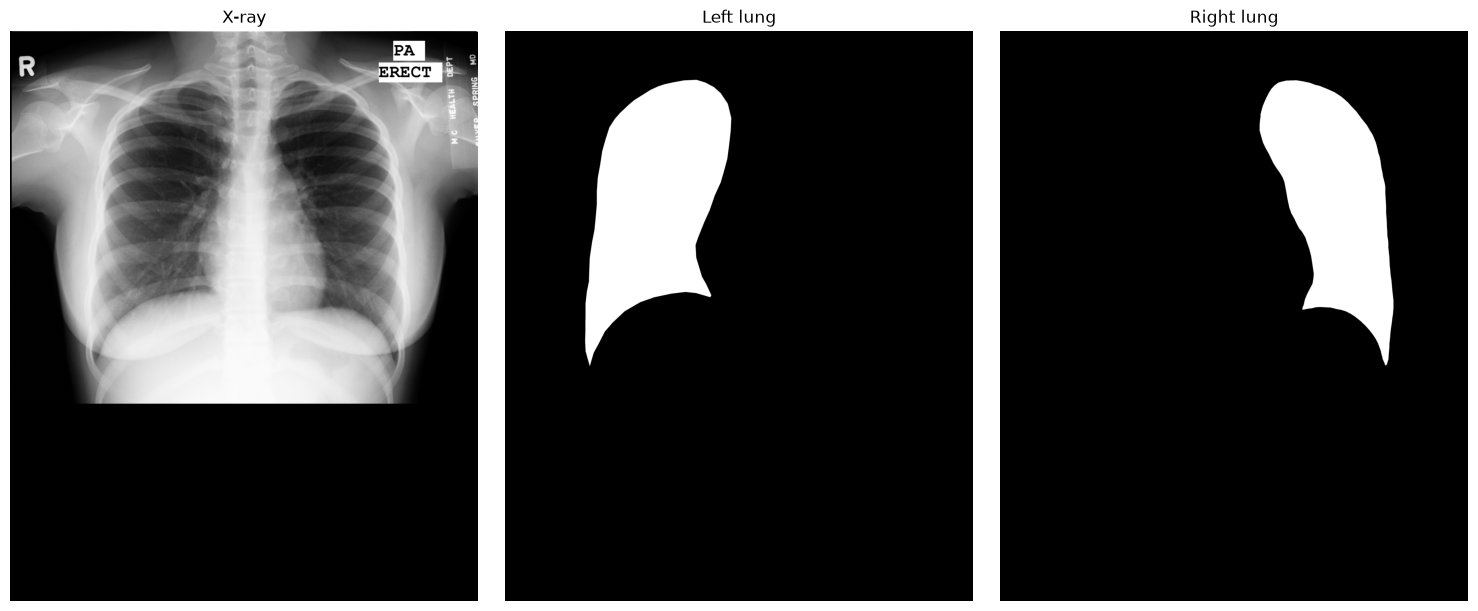

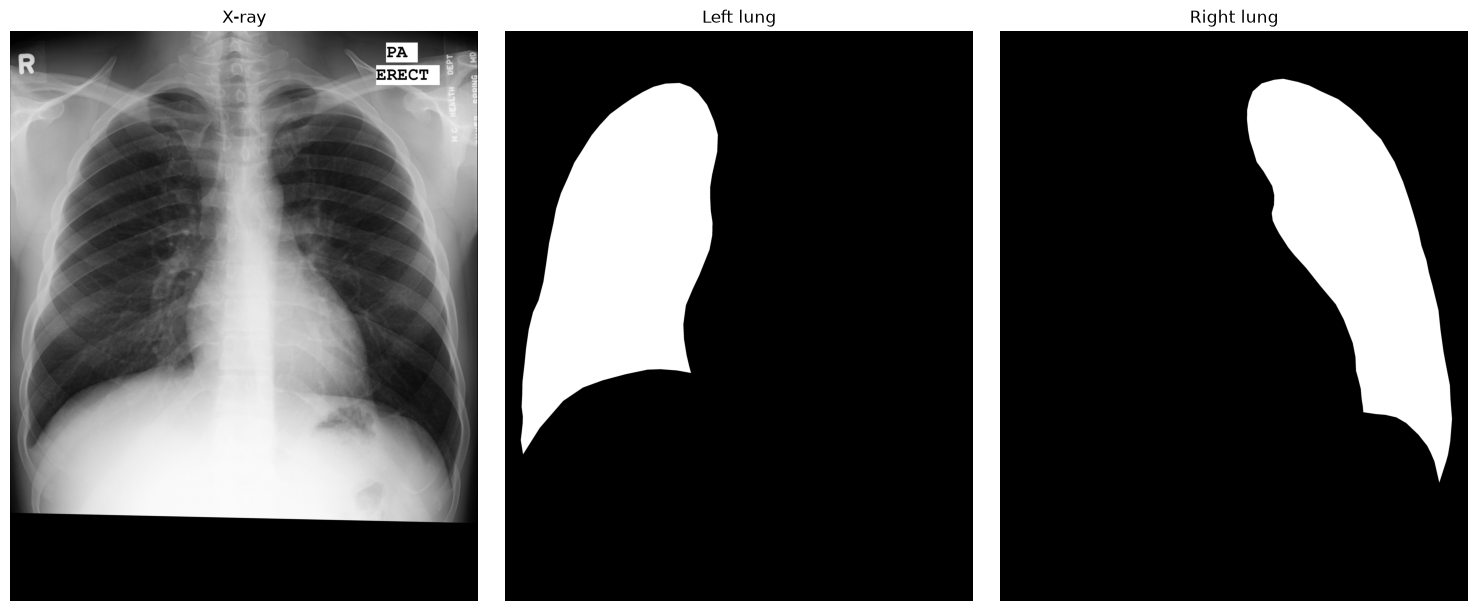

In [4]:
import matplotlib.pyplot as plt

for patient in trial[:5]:
    image = patient.image
    left, right = patient.left_mask, patient.right_mask
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    for ax, pixels, title in zip(axes, [image, left, right], ["X-ray", "Left lung", "Right lung"]):
        ax.imshow(pixels, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()

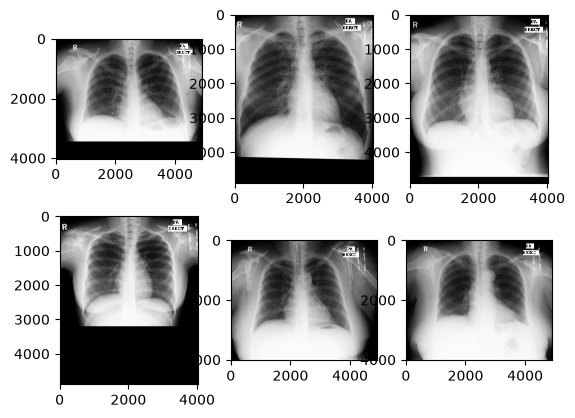

In [5]:
fig2, axs2 = plt.subplots(2,3)
for i, patient in enumerate(trial[:6]):
    image = patient.image
    axs2[i %2 , i %3].imshow(image,  cmap='gray')
    
plt.show()

Mean image threshold images

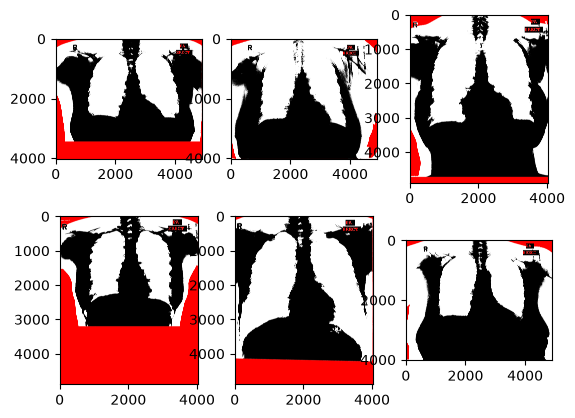

In [7]:
from skimage import filters
import numpy as np
cmap = plt.colormaps["gray"].copy()
cmap.set_bad("red")

fig2, axs2 = plt.subplots(2, 3)

for i, patient in enumerate(trial[:6]):
    image = np.array(patient.image, dtype=np.float32)
    valid = image >= 2
    image[~valid] = np.nan

    thresh = np.nanmean(image)
    image_t = np.where(valid, image < thresh, np.nan)

    axs2[i // 3, i % 3].imshow(image_t, cmap=cmap, vmin=0, vmax=1)
    
plt.show()
    
# filters.threshold_mean()


Histograms for each of the above

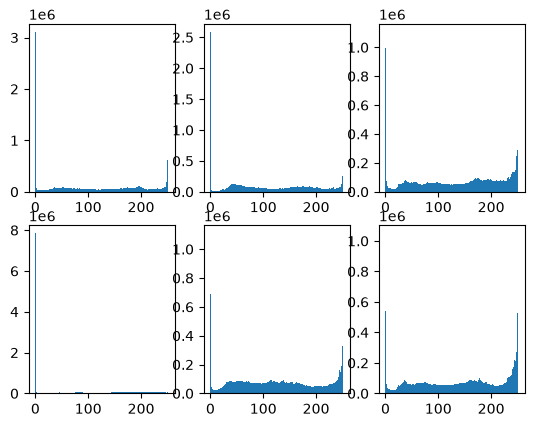

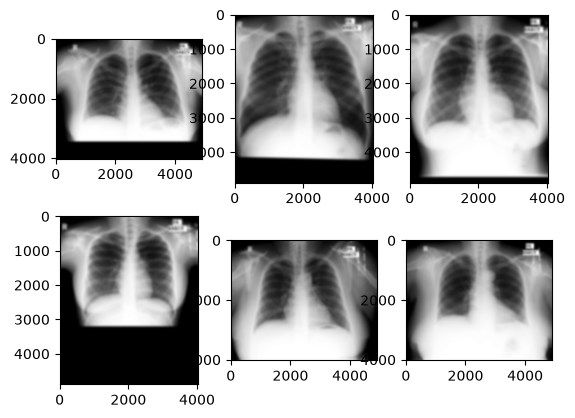

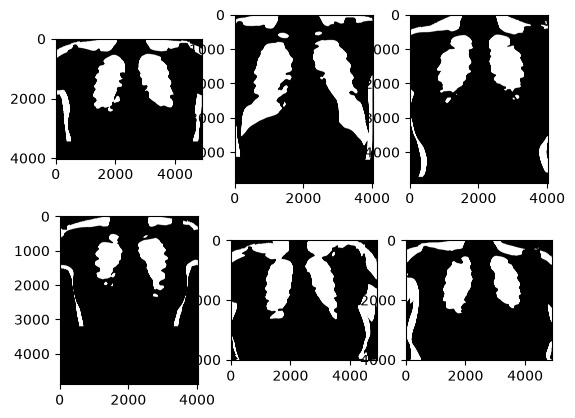

In [9]:
fig2, axs2 = plt.subplots(2,3)
fig3, axs3 = plt.subplots(2,3)
fig4, axs4 = plt.subplots(2,3)
from scipy.ndimage import gaussian_filter
for i, patient in enumerate(trial[:6]):
    # image = np.array(patient.image, dtype=np.float32)
    # image[image<2] = np.nan
    # image = gaussian_filter()
    # image = image.ravel()

    image = np.asarray(patient.image, dtype=np.float32)
    valid = np.isfinite(image) & (image >= 10)

    sigma = 30  # Blur scale in pixels; increase for stronger smoothing

    blurred = gaussian_filter(np.where(valid, image, 0), sigma=sigma)
    weights = gaussian_filter(valid.astype(np.float32), sigma=sigma)

    smoothed = np.full_like(image, np.nan)
    np.divide(blurred, weights, out=smoothed, where=valid & (weights > 0))

    candidate = valid & (smoothed < 80)
    axs2[i %2 , i %3].hist(blurred.ravel(), bins=256)
    axs3[i%2, i%3].imshow(blurred, cmap=cmap)
    axs4[i%2, i%3].imshow(candidate, cmap=cmap)

    
plt.show()

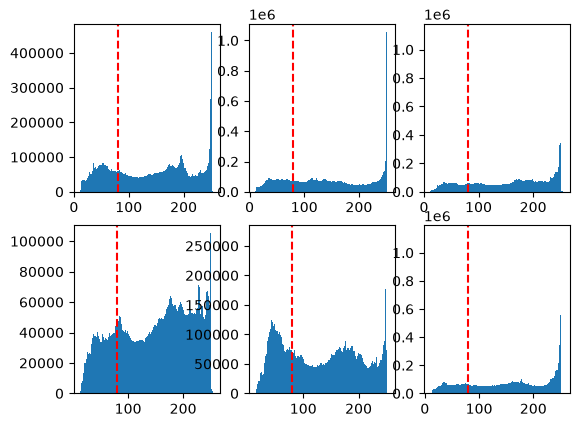

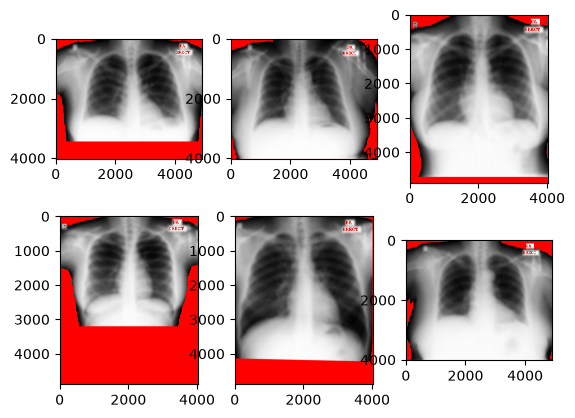

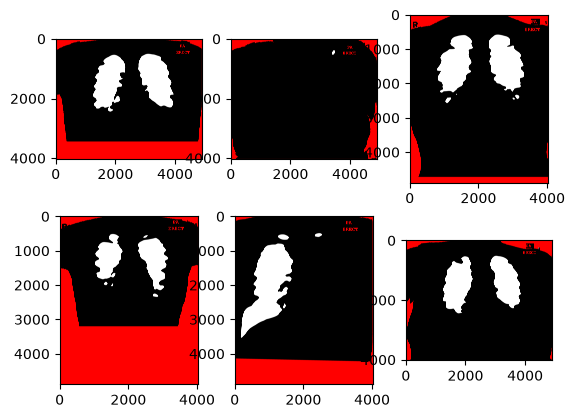

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, binary_dilation
from skimage import measure

fig2, axs2 = plt.subplots(2, 3)
fig3, axs3 = plt.subplots(2, 3)
fig4, axs4 = plt.subplots(2, 3)

cmap = plt.colormaps["gray"].copy()
cmap.set_bad("red")

for i, patient in enumerate(trial[:6]):
    image = np.asarray(patient.image, dtype=np.float32)
    valid = np.isfinite(image) & (image >= 10)

    sigma = 30
    blurred = gaussian_filter(np.where(valid, image, 0), sigma=sigma)
    weights = gaussian_filter(valid.astype(np.float32), sigma=sigma)

    smoothed = np.full_like(image, np.nan)
    np.divide(blurred, weights, out=smoothed,
              where=valid & (weights > 0))

    candidate = valid & (smoothed < 80)
    labels = measure.label(candidate, connectivity=2)
    keep = np.zeros(labels.max() + 1, dtype=bool)
    h, w = image.shape

    for region in measure.regionprops(labels):
        y0, x0, y1, x1 = region.bbox

        # Discard components touching any image edge.
        if y0 == 0 or x0 == 0 or y1 == h or x1 == w:
            continue

        # Inspect the component plus a one-pixel margin.
        crop = np.s_[y0 - 1:y1 + 1, x0 - 1:x1 + 1]
        component = labels[crop] == region.label
        neighbours = binary_dilation(
            component, structure=np.ones((3, 3), dtype=bool)
        )

        invalid_contacts = np.count_nonzero(neighbours & ~valid[crop])
        keep[region.label] = invalid_contacts <= 100

    cleaned = keep[labels]

    axs2.flat[i].hist(smoothed[np.isfinite(smoothed)], bins=256)
    axs2.flat[i].axvline(80, color="red", linestyle="--")
    axs3.flat[i].imshow(smoothed, cmap=cmap)
    axs4.flat[i].imshow(
        np.where(valid, cleaned.astype(float), np.nan),
        cmap=cmap, vmin=0, vmax=1
    )

plt.show()

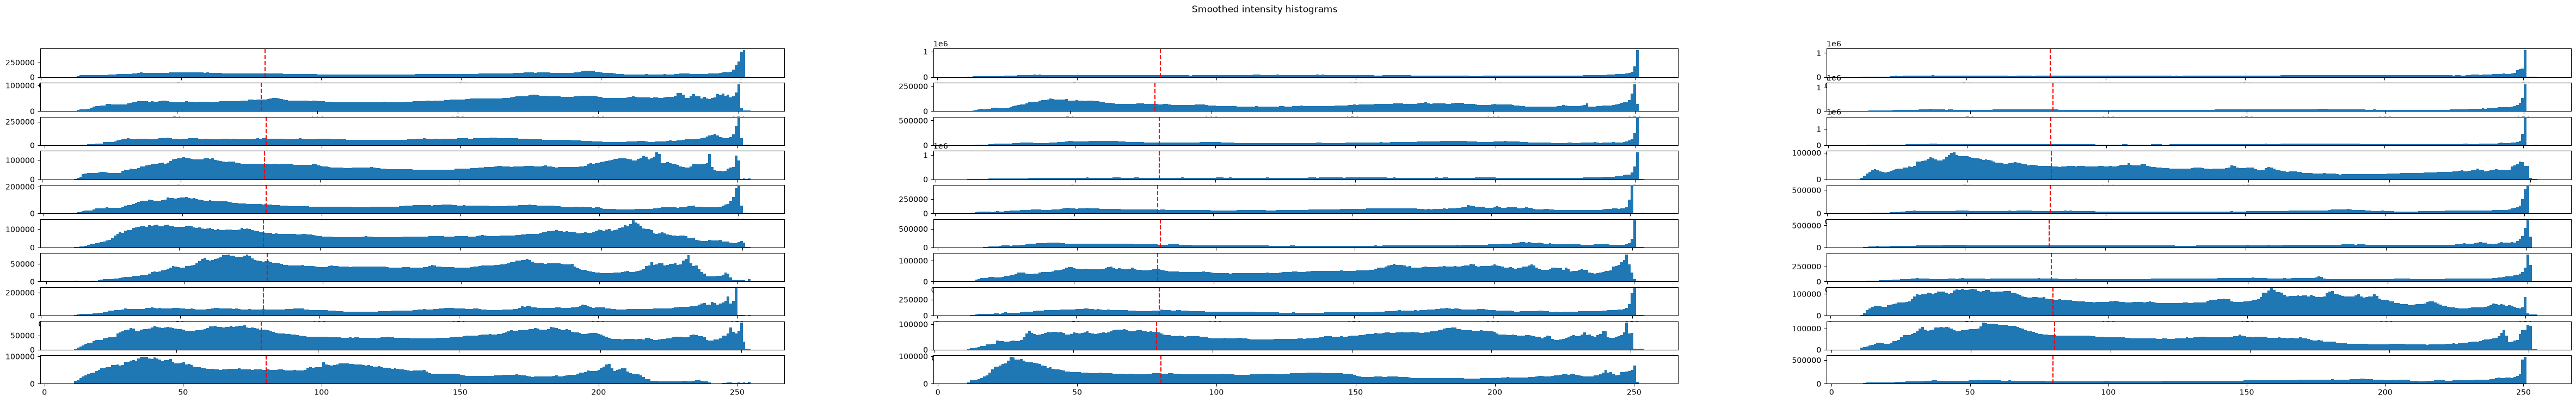

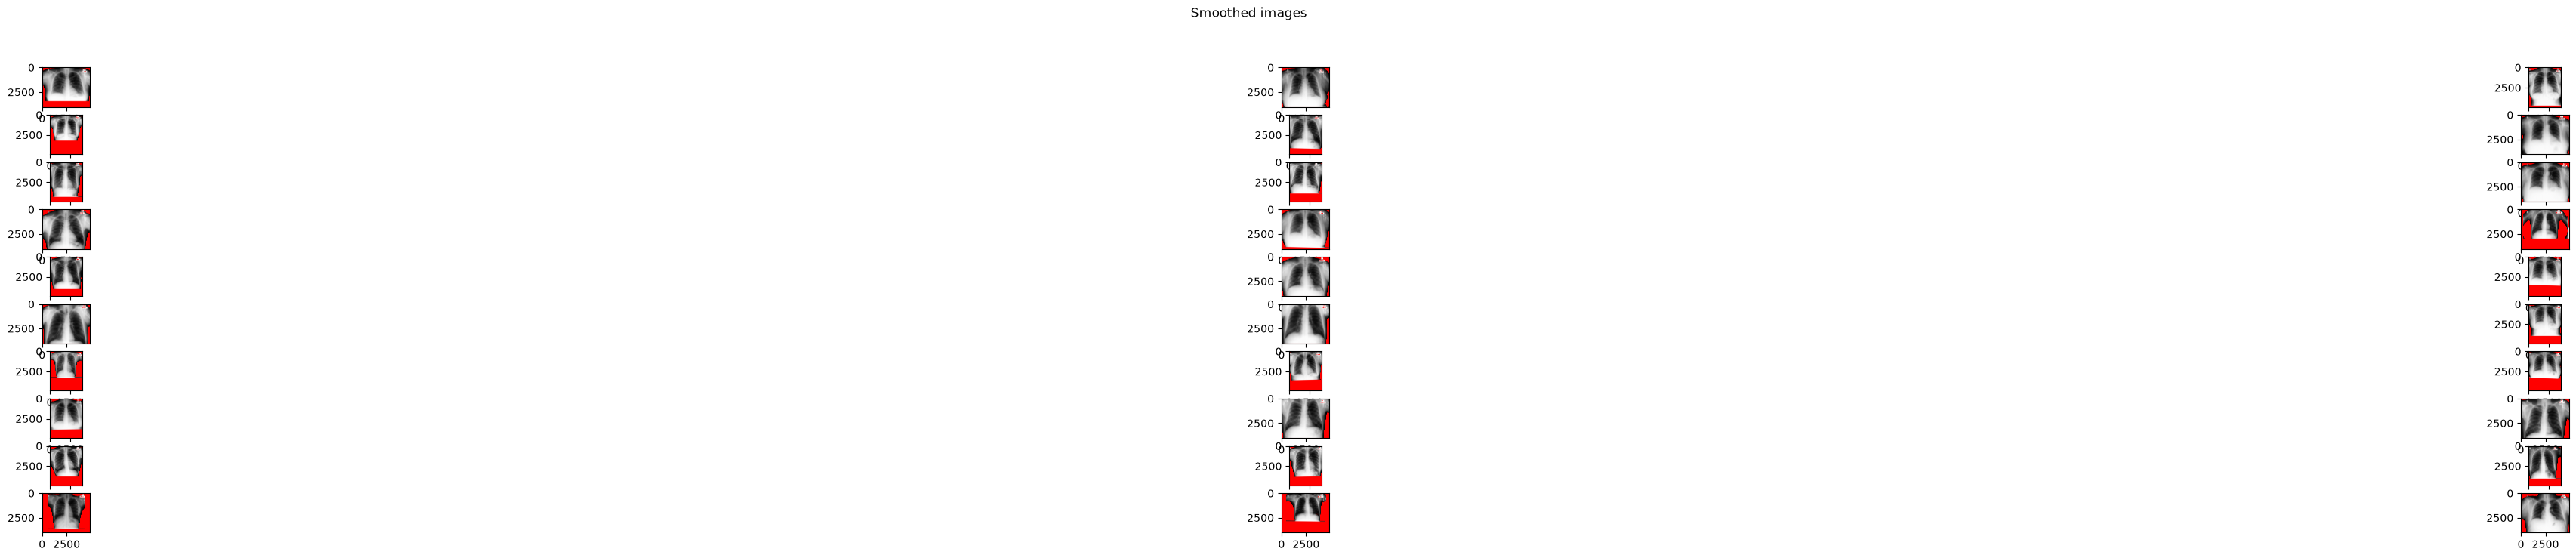

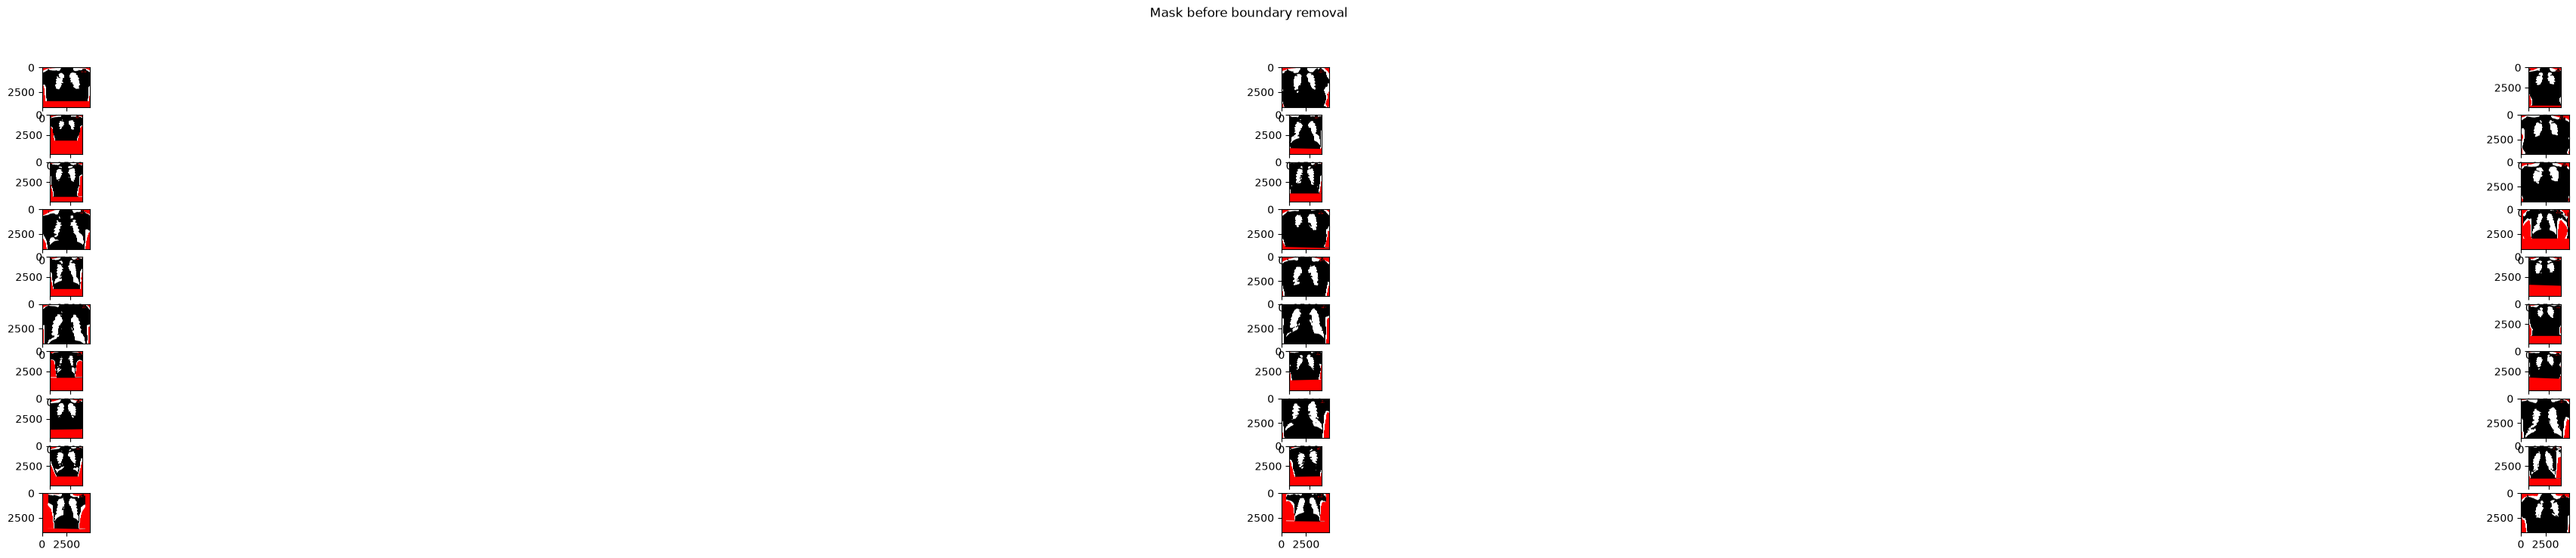

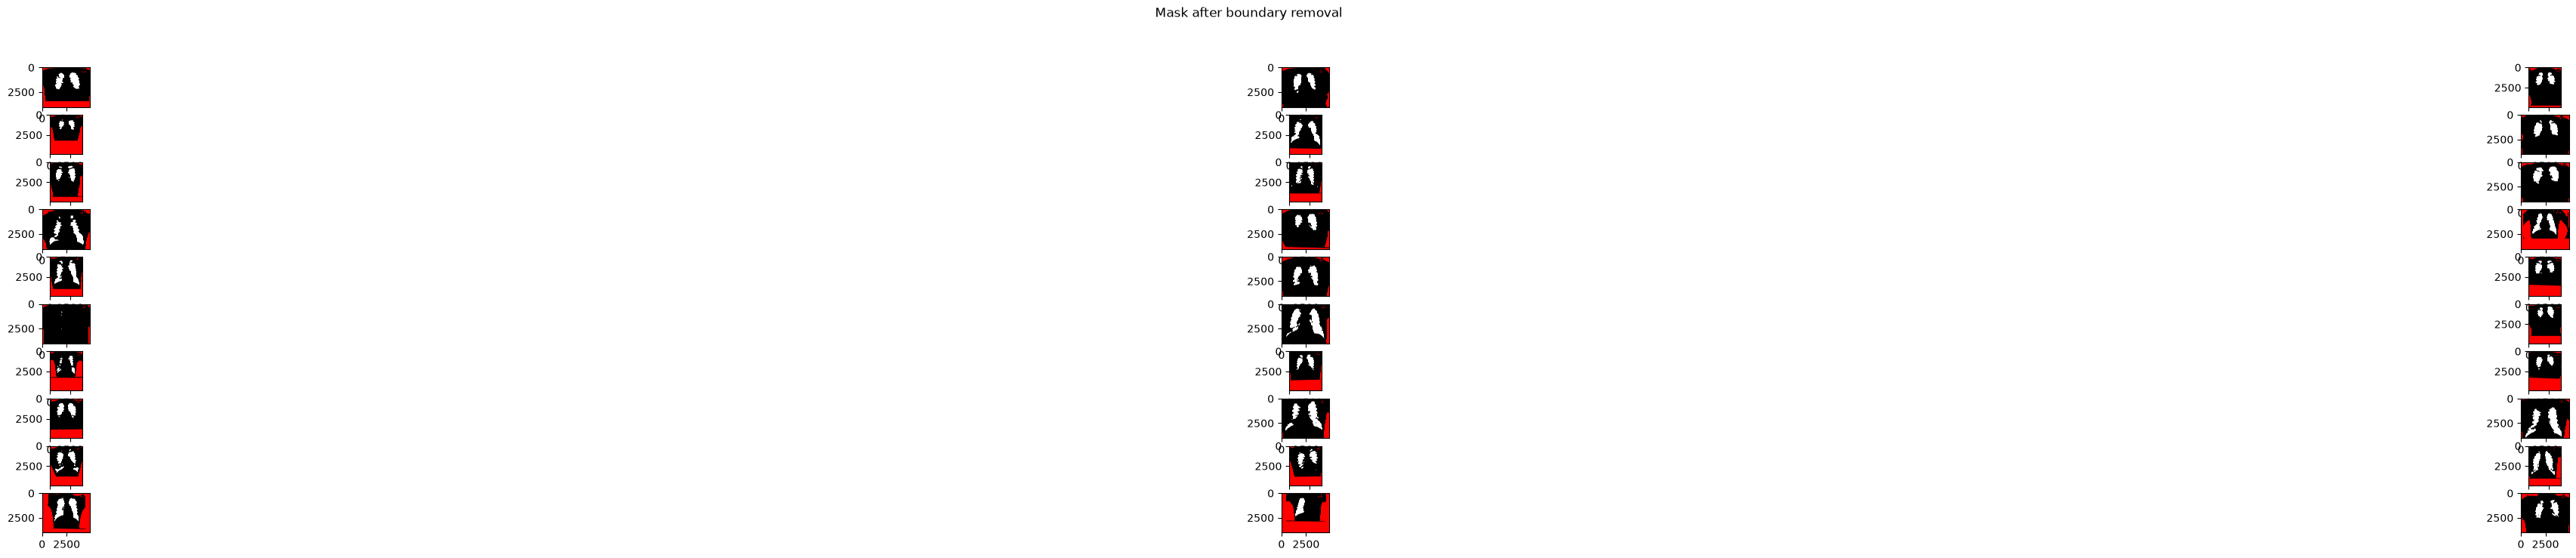

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, binary_dilation
from skimage import measure

fig2, axs2 = plt.subplots(10, 3, figsize=(60, 8))
fig3, axs3 = plt.subplots(10, 3, figsize=(60, 8))
fig4, axs4 = plt.subplots(10, 3, figsize=(60, 8))
fig5, axs5 = plt.subplots(10, 3, figsize=(60, 8))

fig2.suptitle("Smoothed intensity histograms")
fig3.suptitle("Smoothed images")
fig4.suptitle("Mask before boundary removal")
fig5.suptitle("Mask after boundary removal")

cmap = plt.colormaps["gray"].copy()
cmap.set_bad("red")

for i, patient in enumerate(trial[:30]):
    image = np.asarray(patient.image, dtype=np.float32)
    valid = np.isfinite(image) & (image >= 10)

    sigma = 30
    blurred = gaussian_filter(np.where(valid, image, 0), sigma=sigma)
    weights = gaussian_filter(valid.astype(np.float32), sigma=sigma)

    smoothed = np.full_like(image, np.nan)
    np.divide(
        blurred, weights, out=smoothed,
        where=valid & (weights > 0)
    )

    candidate = valid & (smoothed < 65)

    # Display the original mask before removing any components.
    axs4.flat[i].imshow(
        np.where(valid, candidate.astype(float), np.nan),
        cmap=cmap, vmin=0, vmax=1
    )

    labels = measure.label(candidate, connectivity=2)
    keep = np.zeros(labels.max() + 1, dtype=bool)
    h, w = image.shape

    for region in measure.regionprops(labels):
        y0, x0, y1, x1 = region.bbox

        if y0 == 0 or x0 == 0 or y1 == h or x1 == w:
            continue

        crop = np.s_[y0 - 1:y1 + 1, x0 - 1:x1 + 1]
        component = labels[crop] == region.label
        neighbours = binary_dilation(
            component, structure=np.ones((3, 3), dtype=bool)
        )

        invalid_contacts = np.count_nonzero(neighbours & ~valid[crop])
        keep[region.label] = invalid_contacts <= 100

    cleaned = keep[labels]

    axs2.flat[i].hist(smoothed[np.isfinite(smoothed)], bins=256)
    axs2.flat[i].axvline(80, color="red", linestyle="--")
    axs3.flat[i].imshow(smoothed, cmap=cmap)
    axs5.flat[i].imshow(
        np.where(valid, cleaned.astype(float), np.nan),
        cmap=cmap, vmin=0, vmax=1
    )

plt.show()

manual threshold

NameError: name 'cmap' is not defined

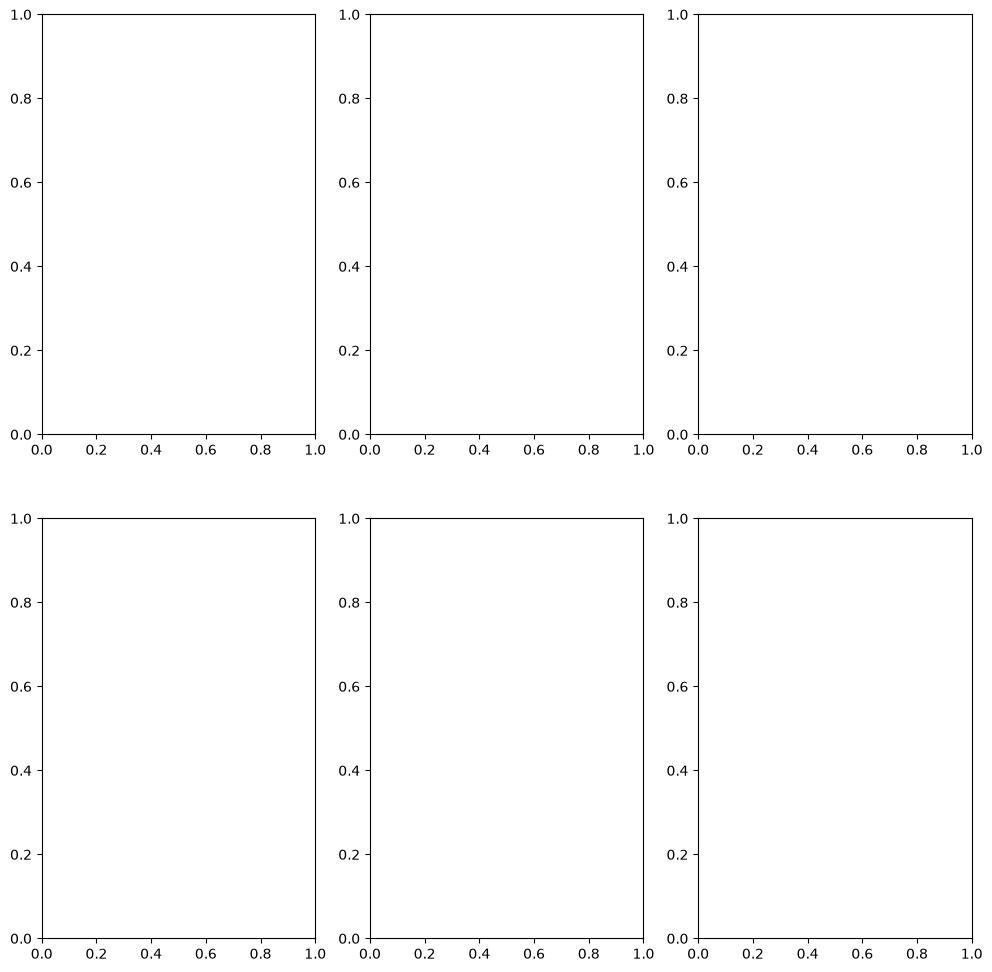

In [2]:
import matplotlib.pyplot as plt
import numpy as np
fig2, axs2 = plt.subplots(2, 3)
fig2.set_size_inches(12, 12)
from skimage import morphology

for i, patient in enumerate(trial[:6]):
    image = np.array(patient.image, dtype=np.float32)
    valid = image >= 10
    image[~valid] = np.nan

    thresh = 40
    # image_t = np.where(valid, image <= thresh, np.nan)
    valid = valid & (image<thresh)
    # selem = disk(50)
    # image_td = closing(image_t, selem)
    image_t = morphology.remove_small_holes(valid, max_size=1000)
    # image_t = morphology.closing(image_t, morphology.disk(20))

    axs2[i // 3, i % 3].imshow(image_t, cmap=cmap, vmin=0, vmax=1)

plt.show()

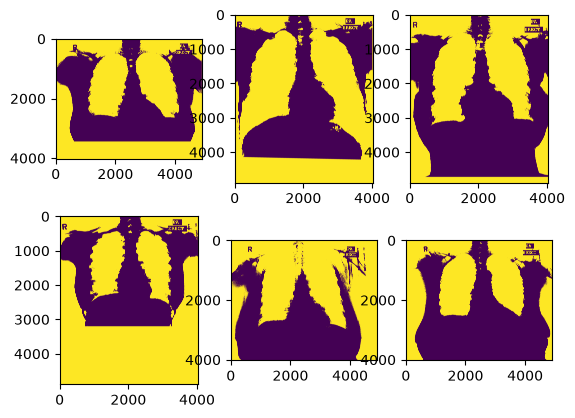

In [18]:
fig2, axs2 = plt.subplots(2,3)
for i, patient in enumerate(trial[:6]):
    image = np.array(patient.image, dtype=np.float32)
    image[image<2] = np.nan
    clean_pixels = image.ravel()[~np.isnan(image.ravel())]
    thresh = filters.threshold_otsu(clean_pixels)
    image_t = ~(image > thresh)
    image_t = np.where(image==np.nan, np.nan, image_t)
    axs2[i %2 , i %3].imshow(image_t)
    
plt.show()

removing areas which touch NaN values

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import binary_dilation
from skimage import measure

cmap = plt.colormaps["gray"].copy()
cmap.set_bad("red")

fig2, axs2 = plt.subplots(20, 3, figsize=(12, 120))

min_pixels = 2000
thresh = 60

for i, patient in enumerate(trial[:60]):
    image = np.asarray(patient.image, dtype=np.float32)
    valid = np.isfinite(image) & (image >= 10)
    candidate = valid & (image < thresh)

    labels = measure.label(candidate, connectivity=2)
    sizes = np.bincount(labels.ravel())

    # Find components adjacent to invalid pixels, including diagonally.
    near_invalid = binary_dilation(~valid, structure=np.ones((3, 3), dtype=bool))
    nan_touching_labels = np.unique(labels[near_invalid])
    nan_touching_labels = nan_touching_labels[nan_touching_labels != 0]

    # Remove small components and entire components touching invalid pixels.
    cleaned = (
        candidate
        & (sizes[labels] >= min_pixels)
        & ~np.isin(labels, nan_touching_labels)
    )

    display = np.where(valid, cleaned.astype(float), np.nan)
    axs2.flat[i].imshow(display, cmap=cmap, vmin=0, vmax=1)

plt.show()

KeyboardInterrupt: 